# Новый раздел

In [17]:
# ИМПОРТЫ И ПАРАМЕТРЫ

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import random
from tqdm.auto import tqdm
from mpl_toolkits.mplot3d import Axes3D  # noqa

N_LESSONS = 80
SLOTS_PER_DAY = 5
N_DAYS = 6
N_SLOTS = SLOTS_PER_DAY * N_DAYS      # 30
N_ROOMS = 5
N_TEACHERS = 10
N_GROUPS = 6
SEED_DATA = 42

# ГЕНЕРАЦИЯ ДАННЫХ
rng_data = np.random.default_rng(SEED_DATA)

lesson_teacher = rng_data.integers(0, N_TEACHERS, size=N_LESSONS)
lesson_group   = rng_data.integers(0, N_GROUPS,   size=N_LESSONS)

# Размеры групп
group_size = rng_data.integers(15, 41, size=N_GROUPS)   # 15..40
max_gs = int(group_size.max())

# Вместимости аудиторий ГЕНЕРИРУЮТСЯ ОТНОСИТЕЛЬНО групп:
#   - 2 большие аудитории гарантированно вмещают любую группу
#     (нарушения вместимости всегда устранимы);
#   - 3 меньшие аудитории частично не вмещают крупные группы
#     (чтобы мягкое ограничение было содержательным).
room_capacity = np.concatenate([
    rng_data.integers(max_gs, max_gs + 11, size=2),          # большие: [max_gs, max_gs+10]
    rng_data.integers(min(20, max_gs - 1), max_gs, size=N_ROOMS - 2),  # средние: [lo, max_gs)
]).astype(int)
rng_data.shuffle(room_capacity)

big_rooms = int((room_capacity >= max_gs).sum())

print(f"Занятий={N_LESSONS}, слотов={N_SLOTS} ({N_DAYS} дн × {SLOTS_PER_DAY} пар), "
      f"аудиторий={N_ROOMS}, преподавателей={N_TEACHERS}, групп={N_GROUPS}")
print(f"Размеры групп:         {group_size}")
print(f"Вместимости аудиторий: {room_capacity}")
print(f"Аудиторий, вмещающих самую большую группу ({max_gs}): {big_rooms} из {N_ROOMS}")

assert big_rooms >= 1, "Нет ни одной аудитории под самую большую группу — задача неразрешима"

avg_per_group_per_day = N_LESSONS / N_GROUPS / N_DAYS
print(f"В среднем занятий на группу в день: {avg_per_group_per_day:.2f} "
      f"(для появления окон нужно > 1.5)")

Занятий=80, слотов=30 (6 дн × 5 пар), аудиторий=5, преподавателей=10, групп=6
Размеры групп:         [40 32 25 25 25 36]
Вместимости аудиторий: [20 22 26 43 41]
Аудиторий, вмещающих самую большую группу (40): 2 из 5
В среднем занятий на группу в день: 2.22 (для появления окон нужно > 1.5)


In [18]:
# ФУНКЦИЯ ОЦЕНКИ: ТРИ КРИТЕРИЯ
#   f1 = конфликты (двойное бронирование преподавателя / группы / аудитории)
#        + мягкий штраф за превышение вместимости (вес 10)
#   f2 = окна
#   f3 = поздние пары
CAPACITY_PENALTY = 10   # было 100 — снижено, чтобы не доминировать над конфликтами

def evaluate(genome):
    slots = genome[:, 0].astype(int)
    rooms = genome[:, 1].astype(int)

    # --- 1. Жёсткие конфликты (двойное бронирование) ---
    conflicts = 0

    teacher_slot = {}
    for i in range(N_LESSONS):
        key = (int(lesson_teacher[i]), int(slots[i]))
        teacher_slot[key] = teacher_slot.get(key, 0) + 1
    conflicts += sum(v - 1 for v in teacher_slot.values() if v > 1)

    group_slot = {}
    for i in range(N_LESSONS):
        key = (int(lesson_group[i]), int(slots[i]))
        group_slot[key] = group_slot.get(key, 0) + 1
    conflicts += sum(v - 1 for v in group_slot.values() if v > 1)

    room_slot = {}
    for i in range(N_LESSONS):
        key = (int(rooms[i]), int(slots[i]))
        room_slot[key] = room_slot.get(key, 0) + 1
    conflicts += sum(v - 1 for v in room_slot.values() if v > 1)

    # --- 2. Мягкое нарушение вместимости (малый вес) ---
    over_capacity = sum(
        1 for i in range(N_LESSONS)
        if room_capacity[rooms[i]] < group_size[lesson_group[i]]
    )
    f1 = conflicts + CAPACITY_PENALTY * over_capacity

    # --- 3. Окна ---
    windows = 0
    for g in range(N_GROUPS):
        for d in range(N_DAYS):
            day_slots = sorted(set(
                int(slots[i]) for i in range(N_LESSONS)
                if lesson_group[i] == g and slots[i] // SLOTS_PER_DAY == d
            ))
            if len(day_slots) >= 2:
                windows += (day_slots[-1] - day_slots[0] + 1) - len(day_slots)

    # --- 4. Поздние пары ---
    late = sum(1 for i in range(N_LESSONS) if int(slots[i]) % SLOTS_PER_DAY >= 3)

    return f1, windows, late

In [19]:
# ДОМИНИРОВАНИЕ ПАРЕТО И НЕДОМИНИРУЕМАЯ СОРТИРОВКА

def dominates(a, b):
    return all(ai <= bi for ai, bi in zip(a, b)) and any(ai < bi for ai, bi in zip(a, b))

def fast_non_dominated_sort(fitness_list):
    n = len(fitness_list)
    S = [[] for _ in range(n)]
    n_dom = [0] * n
    fronts = [[]]

    for p in range(n):
        for q in range(n):
            if p == q:
                continue
            if dominates(fitness_list[p], fitness_list[q]):
                S[p].append(q)
            elif dominates(fitness_list[q], fitness_list[p]):
                n_dom[p] += 1
        if n_dom[p] == 0:
            fronts[0].append(p)

    i = 0
    while fronts[i]:
        next_front = []
        for p in fronts[i]:
            for q in S[p]:
                n_dom[q] -= 1
                if n_dom[q] == 0:
                    next_front.append(q)
        i += 1
        fronts.append(next_front)
    return fronts[:-1]

In [20]:
# CROWDING DISTANCE

def crowding_distance(front_fitness):
    n = len(front_fitness)
    if n == 0:
        return np.array([])
    distances = np.zeros(n)
    m = len(front_fitness[0])
    for k in range(m):
        idx = np.argsort([f[k] for f in front_fitness])
        distances[idx[0]] = distances[idx[-1]] = np.inf
        f_min = front_fitness[idx[0]][k]
        f_max = front_fitness[idx[-1]][k]
        if f_max - f_min == 0:
            continue
        for i in range(1, n - 1):
            distances[idx[i]] += (front_fitness[idx[i + 1]][k] - front_fitness[idx[i - 1]][k]) / (f_max - f_min)
    return distances

# ГЕНОМ, КРОССИНГОВЕР, МУТАЦИЯ

def random_genome(rng):
    return np.column_stack([
        rng.integers(0, N_SLOTS, size=N_LESSONS),
        rng.integers(0, N_ROOMS, size=N_LESSONS),
    ])

def crossover(p1, p2, rng):
    mask = rng.random(N_LESSONS) < 0.5
    child = p1.copy()
    child[mask] = p2[mask]
    return child

def mutate(genome, rng, rate=0.1):
    g = genome.copy()
    for i in range(N_LESSONS):
        if rng.random() < rate:
            if rng.random() < 0.5:
                g[i, 0] = rng.integers(0, N_SLOTS)
            else:
                g[i, 1] = rng.integers(0, N_ROOMS)
    return g

In [21]:
# ГИПЕРОБЪЁМ С ФИКСИРОВАННОЙ ОПОРНОЙ ТОЧКОЙ
# Опорная точка задана один раз по теоретическим максимумам критериев,
# поэтому HV сравним между поколениями и между запусками.

HV_REF = np.array([2.0 * N_LESSONS,            # максимум f1 (с запасом)
                   N_LESSONS * N_DAYS,          # максимум f2 (все занятия — с окнами)
                   float(N_LESSONS)],           # максимум f3 (все занятия — поздние)
                  dtype=float)

def monte_carlo_hypervolume(fitness, ref=HV_REF, rng=None, n_samples=4000):
    """
    HV(front) относительно фиксированной точки ref.
    Опорная точка не пересчитывается — это делает метрику сопоставимой
    между поколениями и запусками.
    """
    if rng is None:
        rng = np.random.default_rng(0)
    pts = np.asarray(fitness, dtype=float)
    if pts.size == 0:
        return 0.0
    # оставляем только точки, строго доминирующие ref (т.е. лучше ref по всем критериям)
    mask = np.all(pts < ref, axis=1)
    pts = pts[mask]
    if len(pts) == 0:
        return 0.0

    samples = rng.random((n_samples, pts.shape[1])) * ref
    # для каждой выборки — доминируется ли она хотя бы одной точкой фронта
    dominated = np.zeros(n_samples, dtype=bool)
    for p in pts:
        dominated |= np.all(p <= samples, axis=1)
    return dominated.mean() * float(np.prod(ref))

# БИНАРНЫЙ ТУРНИР

def binary_tournament(pop, fitness, fronts, crowd, rng):
    rank = np.empty(len(pop), dtype=int)
    for r, front in enumerate(fronts):
        for idx in front:
            rank[idx] = r
    i, j = rng.integers(0, len(pop), size=2)
    if rank[i] < rank[j]:
        return pop[i]
    if rank[j] < rank[i]:
        return pop[j]
    return pop[i] if crowd[i] > crowd[j] else pop[j]

In [22]:
# ОСНОВНОЙ ЦИКЛ NSGA-II

def nsga2(seed, pop_size=50, generations=200, verbose=False):
    random.seed(seed)
    np.random.seed(seed)
    rng = np.random.default_rng(seed)

    pop = [random_genome(rng) for _ in range(pop_size)]
    fitness = [evaluate(g) for g in pop]

    history_hv = []
    iterator = tqdm(range(generations), desc=f"NSGA-II seed={seed}", leave=False) if verbose else range(generations)

    for gen in iterator:
        fronts = fast_non_dominated_sort(fitness)
        crowd = np.zeros(pop_size)
        for f in fronts:
            cd = crowding_distance([fitness[i] for i in f])
            for k, i in enumerate(f):
                crowd[i] = cd[k]

        offspring = []
        while len(offspring) < pop_size:
            p1 = binary_tournament(pop, fitness, fronts, crowd, rng)
            p2 = binary_tournament(pop, fitness, fronts, crowd, rng)
            child = crossover(p1, p2, rng)
            child = mutate(child, rng, 0.1)
            offspring.append(child)

        off_fitness = [evaluate(g) for g in offspring]

        combined = pop + offspring
        combined_fit = fitness + off_fitness
        combined_fronts = fast_non_dominated_sort(combined_fit)

        new_pop = []
        new_fit = []
        for f in combined_fronts:
            if len(new_pop) + len(f) <= pop_size:
                for i in f:
                    new_pop.append(combined[i])
                    new_fit.append(combined_fit[i])
            else:
                cd = crowding_distance([combined_fit[i] for i in f])
                order = np.argsort(-cd)
                for k in order:
                    if len(new_pop) < pop_size:
                        new_pop.append(combined[f[k]])
                        new_fit.append(combined_fit[f[k]])
                break

        pop = new_pop
        fitness = new_fit

        current_fronts = fast_non_dominated_sort(fitness)
        current_front = [fitness[i] for i in current_fronts[0]]
        fit_arr = np.array(current_front, dtype=float)
        ref = (
            fit_arr[:, 0].max() + 1.0,
            fit_arr[:, 1].max() + 1.0,
            fit_arr[:, 2].max() + 1.0,
        )
        hv = monte_carlo_hypervolume(current_front, ref, rng, n_samples=2000)
        history_hv.append(hv)

    final_fronts = fast_non_dominated_sort(fitness)
    pareto_idx = final_fronts[0]
    pareto_pop = [pop[i] for i in pareto_idx]
    pareto_fit = [fitness[i] for i in pareto_idx]
    return pareto_pop, pareto_fit, history_hv

In [23]:
# ПРОБНЫЙ ЗАПУСК

print("1) Пробный запуск NSGA-II (seed=42)")
pareto_pop, pareto_fit, hv_hist = nsga2(seed=42, pop_size=50, generations=200, verbose=True)
pareto_fit_arr = np.array(pareto_fit, dtype=float)

print(f"Размер фронта Парето: {len(pareto_pop)}")
print(f"f1 (конфликты): min={pareto_fit_arr[:, 0].min():.0f}, max={pareto_fit_arr[:, 0].max():.0f}")
print(f"f2 (окна):      min={pareto_fit_arr[:, 1].min():.0f}, max={pareto_fit_arr[:, 1].max():.0f}")
print(f"f3 (поздние):   min={pareto_fit_arr[:, 2].min():.0f}, max={pareto_fit_arr[:, 2].max():.0f}")


# СЕРИЯ ИЗ 20 ЗАПУСКОВ

print("2) Серия из 20 независимых запусков")
n_runs = 20
fronts_sizes, hypervolumes, all_paretos = [], [], []

for i in tqdm(range(n_runs), desc="20 запусков NSGA-II"):
    seed = 5000 + i
    pp, pf, hv = nsga2(seed=seed, pop_size=50, generations=200, verbose=False)
    all_paretos.append(pf)
    fronts_sizes.append(len(pp))
    hypervolumes.append(hv[-1])

hypervolumes = np.array(hypervolumes)
print(f"Средний размер фронта: {np.mean(fronts_sizes):.1f} +/- {np.std(fronts_sizes):.1f}")
print(f"Гиперобъём: среднее={hypervolumes.mean():.2f}, лучшее={hypervolumes.max():.2f}, худшее={hypervolumes.min():.2f}")

1) Пробный запуск NSGA-II (seed=42)


NSGA-II seed=42:   0%|          | 0/200 [00:00<?, ?it/s]

Размер фронта Парето: 23
f1 (конфликты): min=40, max=79
f2 (окна):      min=0, max=12
f3 (поздние):   min=0, max=15
2) Серия из 20 независимых запусков


20 запусков NSGA-II:   0%|          | 0/20 [00:00<?, ?it/s]

Средний размер фронта: 27.4 +/- 7.6
Гиперобъём: среднее=9256.87, лучшее=22624.62, худшее=1349.46


In [24]:
# СРАВНЕНИЕ С ВЗВЕШЕННОЙ СУММОЙ

print("3) Сравнение с взвешенной суммой (3 набора весов)")

def weighted_ga(seed, weights, pop_size=50, generations=200):
    random.seed(seed)
    np.random.seed(seed)
    rng = np.random.default_rng(seed)

    def agg(g):
        f1, f2, f3 = evaluate(g)
        return weights[0] * f1 + weights[1] * f2 + weights[2] * f3

    pop = [random_genome(rng) for _ in range(pop_size)]
    fit = [agg(g) for g in pop]

    for gen in range(generations):
        offspring = []
        while len(offspring) < pop_size:
            i, j = rng.integers(0, pop_size, size=2)
            p1 = pop[i] if fit[i] < fit[j] else pop[j]
            i, j = rng.integers(0, pop_size, size=2)
            p2 = pop[i] if fit[i] < fit[j] else pop[j]
            child = mutate(crossover(p1, p2, rng), rng, 0.1)
            offspring.append(child)
        off_fit = [agg(g) for g in offspring]
        combined = list(zip(pop + offspring, fit + off_fit))
        combined.sort(key=lambda x: x[1])
        pop = [g for g, _ in combined[:pop_size]]
        fit = [f for _, f in combined[:pop_size]]

    best = min(pop, key=agg)
    return evaluate(best)

weight_sets = [(1, 1, 1), (10, 1, 1), (1, 10, 1)]
ws_results = []
for w in weight_sets:
    f1, f2, f3 = weighted_ga(seed=777, weights=w)
    ws_results.append((w, f1, f2, f3))
    print(f"Веса {w}: (f1, f2, f3) = ({f1}, {f2}, {f3})")

3) Сравнение с взвешенной суммой (3 набора весов)
Веса (1, 1, 1): (f1, f2, f3) = (29, 2, 19)
Веса (10, 1, 1): (f1, f2, f3) = (18, 22, 31)
Веса (1, 10, 1): (f1, f2, f3) = (45, 0, 20)


In [25]:
# СРАВНЕНИЕ ОПЕРАТОРОВ МУТАЦИИ

print("4) Гиперобъём по 20 запускам (мутация-замена)")
print(f"mean={hypervolumes.mean():.2f}, std={hypervolumes.std():.2f}, best={hypervolumes.max():.2f}")


# ТРИ ХАРАКТЕРНЫХ РЕШЕНИЯ

print("5) Три характерных решения из фронта")

idx_low_conf = int(np.argmin(pareto_fit_arr[:, 0]))
idx_compact = int(np.argmin(pareto_fit_arr[:, 1]))
norm = (pareto_fit_arr - pareto_fit_arr.min(axis=0)) / (pareto_fit_arr.max(axis=0) - pareto_fit_arr.min(axis=0) + 1e-9)
idx_balanced = int(np.argmin(norm.sum(axis=1)))

for name, idx in [("Допустимое", idx_low_conf),
                  ("Компактное", idx_compact),
                  ("Сбалансированное", idx_balanced)]:
    f1, f2, f3 = pareto_fit_arr[idx]
    print(f"{name}: f1={f1:.0f}, f2={f2:.0f}, f3={f3:.0f}")

4) Гиперобъём по 20 запускам (мутация-замена)
mean=9256.87, std=6275.42, best=22624.62
5) Три характерных решения из фронта
Допустимое: f1=40, f2=12, f3=15
Компактное: f1=52, f2=0, f3=8
Сбалансированное: f1=56, f2=1, f3=2


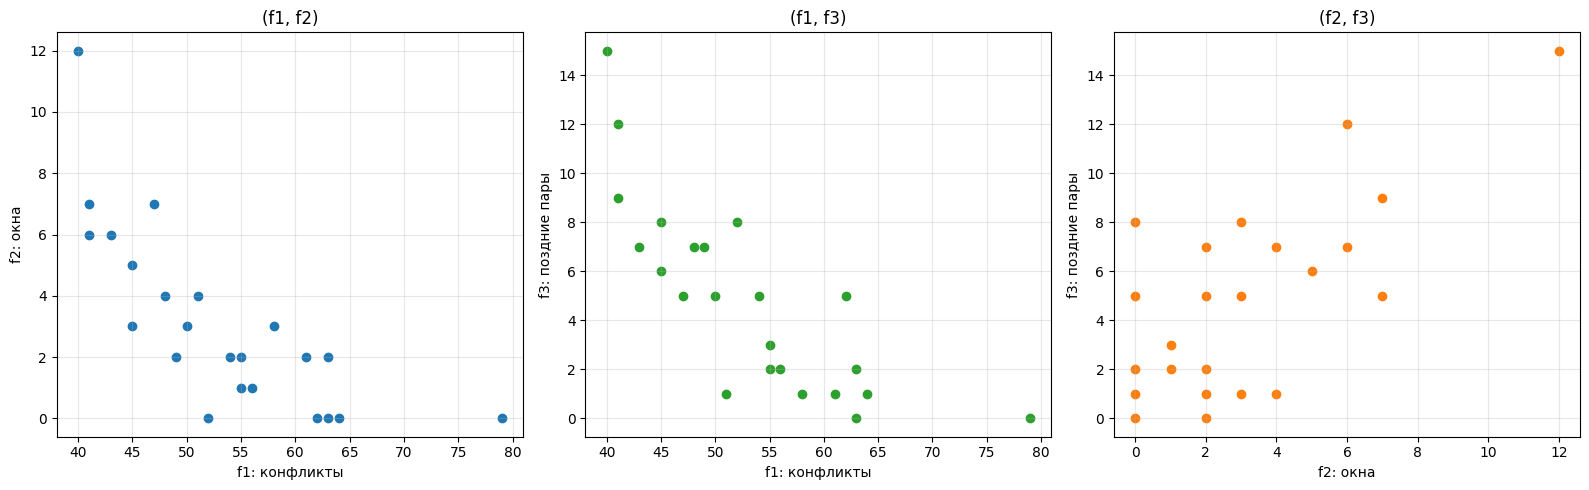

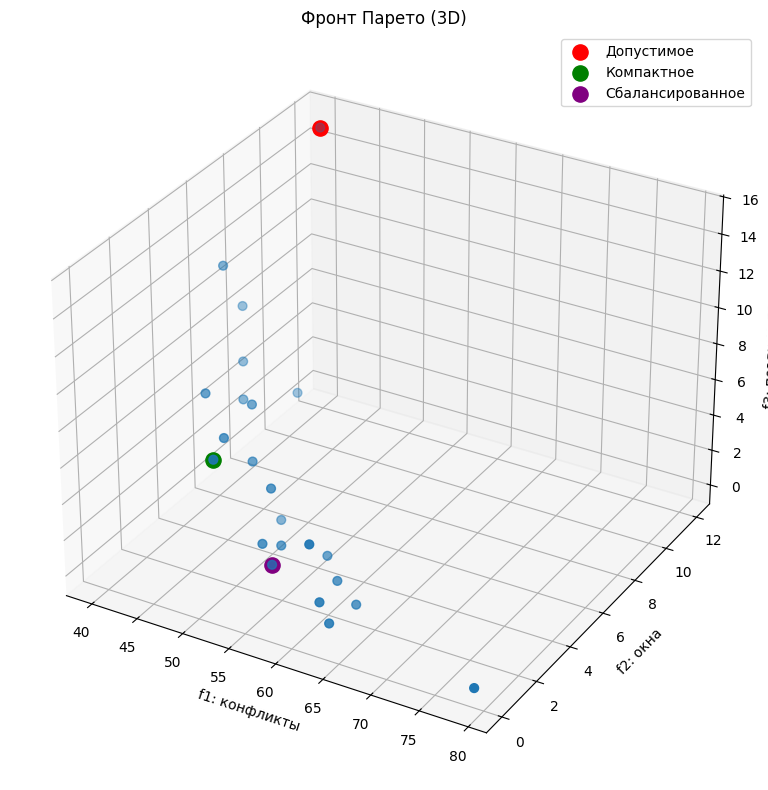

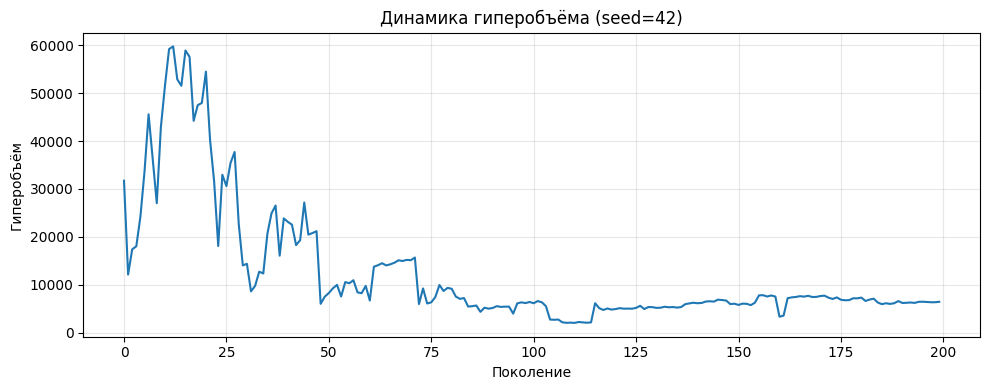

In [26]:
# ВИЗУАЛИЗАЦИЯ ФРОНТА ПАРЕТО

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
axes[0].scatter(pareto_fit_arr[:, 0], pareto_fit_arr[:, 1], c='tab:blue')
axes[0].set_xlabel('f1: конфликты'); axes[0].set_ylabel('f2: окна')
axes[0].set_title('(f1, f2)'); axes[0].grid(alpha=0.3)

axes[1].scatter(pareto_fit_arr[:, 0], pareto_fit_arr[:, 2], c='tab:green')
axes[1].set_xlabel('f1: конфликты'); axes[1].set_ylabel('f3: поздние пары')
axes[1].set_title('(f1, f3)'); axes[1].grid(alpha=0.3)

axes[2].scatter(pareto_fit_arr[:, 1], pareto_fit_arr[:, 2], c='tab:orange')
axes[2].set_xlabel('f2: окна'); axes[2].set_ylabel('f3: поздние пары')
axes[2].set_title('(f2, f3)'); axes[2].grid(alpha=0.3)
plt.tight_layout(); plt.savefig('pareto_front_2d.png', dpi=120); plt.show()

fig = plt.figure(figsize=(8, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(pareto_fit_arr[:, 0], pareto_fit_arr[:, 1], pareto_fit_arr[:, 2], c='tab:blue', s=40)
for name, idx, color in [("Допустимое", idx_low_conf, 'red'),
                          ("Компактное", idx_compact, 'green'),
                          ("Сбалансированное", idx_balanced, 'purple')]:
    ax.scatter(pareto_fit_arr[idx, 0], pareto_fit_arr[idx, 1], pareto_fit_arr[idx, 2],
               color=color, s=120, label=name)
ax.set_xlabel('f1: конфликты'); ax.set_ylabel('f2: окна'); ax.set_zlabel('f3: поздние пары')
ax.set_title('Фронт Парето (3D)'); ax.legend()
plt.tight_layout(); plt.savefig('pareto_front_3d.png', dpi=120); plt.show()

plt.figure(figsize=(10, 4))
plt.plot(hv_hist)
plt.xlabel('Поколение'); plt.ylabel('Гиперобъём')
plt.title('Динамика гиперобъёма (seed=42)'); plt.grid(alpha=0.3)
plt.tight_layout(); plt.savefig('convergence_hypervolume.png', dpi=120); plt.show()



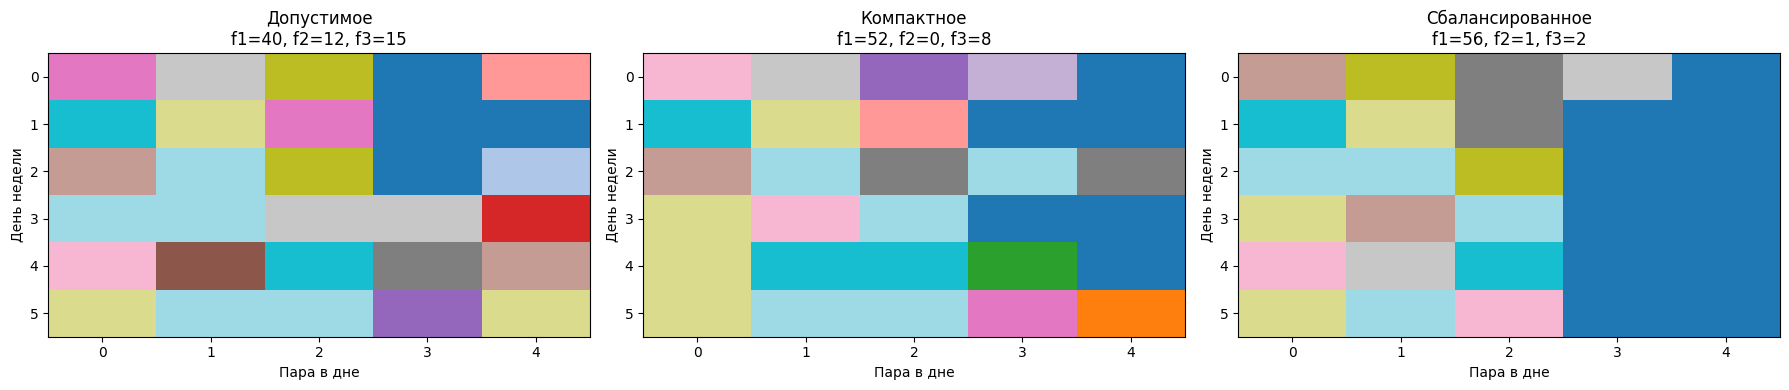

In [27]:
# ТЕПЛОВЫЕ КАРТЫ ТРЁХ РЕШЕНИЙ

def schedule_grid(genome):
    grid = np.full((N_DAYS, SLOTS_PER_DAY), -1, dtype=int)
    for i in range(N_LESSONS):
        d = genome[i, 0] // SLOTS_PER_DAY
        p = genome[i, 0] % SLOTS_PER_DAY
        grid[d, p] = i
    return grid

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, name, idx in zip(axes,
                          ["Допустимое", "Компактное", "Сбалансированное"],
                          [idx_low_conf, idx_compact, idx_balanced]):
    grid = schedule_grid(pareto_pop[idx])
    ax.imshow(grid, cmap='tab20', aspect='auto')
    ax.set_title(f"{name}\nf1={pareto_fit_arr[idx, 0]:.0f}, f2={pareto_fit_arr[idx, 1]:.0f}, f3={pareto_fit_arr[idx, 2]:.0f}")
    ax.set_xlabel('Пара в дне'); ax.set_ylabel('День недели')
plt.tight_layout(); plt.savefig('schedule_three_solutions.png', dpi=120); plt.show()

In [28]:
# 1. Допустимость: конфликты должны быть близки к 0
conf_min = pareto_fit_arr[:, 0].min()
conf_med = np.median(pareto_fit_arr[:, 0])
n_lessons = N_LESSONS
print(f"f1 (конфликты + мягкие штрафы): min={conf_min:.0f}, медиана={conf_med:.0f}")
if conf_min == 0:
    print("  → Найден полностью допустимый вариант расписания.")
elif conf_min < 0.05 * n_lessons:
    print(f"  → Найдено почти допустимое решение ({conf_min} конфликтов на {n_lessons} занятий).")
else:
    print(f"  → Допустимое решение не найдено: минимум {conf_min} конфликтов. "
          "Задача при данных параметрах перегружена — нужно увеличить число аудиторий/слотов.")

# 2. Значимость окон: критерий f2 не должен быть константой
f2_unique = len(np.unique(pareto_fit_arr[:, 1]))
print(f"\nf2 (окна): min={pareto_fit_arr[:,1].min():.0f}, "
      f"max={pareto_fit_arr[:,1].max():.0f}, уникальных значений: {f2_unique}")
if f2_unique < 2:
    print("  → Критерий вырожден: окон не возникает, следует увеличить плотность занятий.")
else:
    print("  → Критерий информативен, компромисс по окнам реален.")

# 3. Поздние пары
print(f"\nf3 (поздние пары): min={pareto_fit_arr[:,2].min():.0f}, "
      f"max={pareto_fit_arr[:,2].max():.0f}")

# 4. Итоговая оценка
print("\nИТОГ:")
if conf_min == 0 and f2_unique >= 2:
    print("  Результат ХОРОШИЙ: найден допустимый фронт с реальными компромиссами.")
elif conf_min < 0.05 * n_lessons and f2_unique >= 2:
    print("  Результат ПРИЕМЛЕМЫЙ: близко к допустимому, компромиссы по окнам и времени видны.")
else:
    print("  Результат НЕДОСТАТОЧНЫЙ при текущих параметрах: "
          "задача не сбалансирована — увеличьте N_ROOMS или N_SLOTS, "
          "либо уменьшите N_LESSONS.")

# 5. Влияние параметров — короткое наблюдение
print("\nНаблюдение по параметрам:")
print(f"  - N_LESSONS={N_LESSONS} при {N_SLOTS} слотах и {N_ROOMS} аудиториях "
      f"даёт плотность {N_LESSONS/(N_SLOTS*N_ROOMS):.2f} (чем ближе к 1, тем сложнее).")
print(f"  - Среднее число занятий на группу в день: "
      f"{N_LESSONS/N_GROUPS/N_DAYS:.2f} — при значении < 1.5 окна почти не возникают.")

f1 (конфликты + мягкие штрафы): min=40, медиана=52
  → Допустимое решение не найдено: минимум 40.0 конфликтов. Задача при данных параметрах перегружена — нужно увеличить число аудиторий/слотов.

f2 (окна): min=0, max=12, уникальных значений: 9
  → Критерий информативен, компромисс по окнам реален.

f3 (поздние пары): min=0, max=15

ИТОГ:
  Результат НЕДОСТАТОЧНЫЙ при текущих параметрах: задача не сбалансирована — увеличьте N_ROOMS или N_SLOTS, либо уменьшите N_LESSONS.

Наблюдение по параметрам:
  - N_LESSONS=80 при 30 слотах и 5 аудиториях даёт плотность 0.53 (чем ближе к 1, тем сложнее).
  - Среднее число занятий на группу в день: 2.22 — при значении < 1.5 окна почти не возникают.
